In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside the notebook
%matplotlib inline



In [6]:
df = pd.read_csv("../data/Nassau Candy Distributor.csv")

In [8]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [9]:
print("Rows and Columns:", df.shape)

Rows and Columns: (10194, 18)


In [10]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Country/Region',
 'City',
 'State/Province',
 'Postal Code',
 'Division',
 'Region',
 'Product ID',
 'Product Name',
 'Sales',
 'Units',
 'Gross Profit',
 'Cost']

In [11]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

In [12]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  str    
 7   City            10194 non-null  str    
 8   State/Province  10194 non-null  str    
 9   Postal Code     10194 non-null  str    
 10  Division        10194 non-null  str    
 11  Region          10194 non-null  str    
 12  Product ID      10194 non-null  str    
 13  Product Name    10194 non-null  str    
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null  float64
dt

In [14]:
# Convert date columns to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Verify
df[["Order Date", "Ship Date"]].dtypes

ValueError: time data "13-01-2024" doesn't match format "%m-%d-%Y". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [15]:
# Convert date columns (DD-MM-YYYY format)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d-%m-%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%d-%m-%Y")

# Verify
print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [16]:
# Calculate shipping time
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

df[["Order Date", "Ship Date", "Shipping Days"]].head()

,Order Date,Ship Date,Shipping Days
0,2024-01-03,2026-06-30,909
1,2024-01-04,2026-07-01,909
2,2024-01-04,2026-07-01,909
3,2024-01-04,2026-07-01,909
4,2024-01-05,2026-07-05,912


In [17]:
print(df["Order Date"].head(10))

0   2024-01-03
1   2024-01-04
2   2024-01-04
3   2024-01-04
4   2024-01-05
5   2024-01-06
6   2024-01-06
7   2024-01-06
8   2024-01-06
9   2024-01-06
Name: Order Date, dtype: datetime64[us]


In [18]:
print(df["Ship Date"].head(10))

0   2026-06-30
1   2026-07-01
2   2026-07-01
3   2026-07-01
4   2026-07-05
5   2026-07-03
6   2026-07-03
7   2026-06-30
8   2026-07-03
9   2026-07-03
Name: Ship Date, dtype: datetime64[us]


In [19]:
# Reload the original CSV
df = pd.read_csv("../data/Nassau Candy Distributor.csv")

# Show the original text values
print(df.loc[:9, ["Order Date", "Ship Date"]])

   Order Date   Ship Date
0  03-01-2024  30-06-2026
1  04-01-2024  01-07-2026
2  04-01-2024  01-07-2026
3  04-01-2024  01-07-2026
4  05-01-2024  05-07-2026
5  06-01-2024  03-07-2026
6  06-01-2024  03-07-2026
7  06-01-2024  30-06-2026
8  06-01-2024  03-07-2026
9  06-01-2024  03-07-2026


In [20]:
print("Total Sales : $", round(df["Sales"].sum(),2))
print("Total Profit: $", round(df["Gross Profit"].sum(),2))
print("Total Cost  : $", round(df["Cost"].sum(),2))
print("Total Units :", df["Units"].sum())

Total Sales : $ 141783.63
Total Profit: $ 93442.8
Total Cost  : $ 48340.83
Total Units : 38654


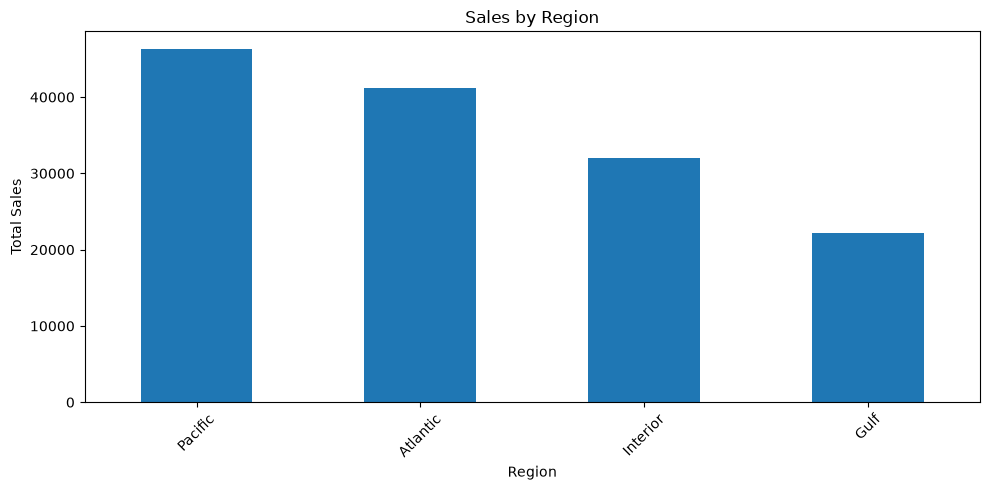

In [21]:
import matplotlib.pyplot as plt

region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))
region_sales.plot(kind="bar")
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

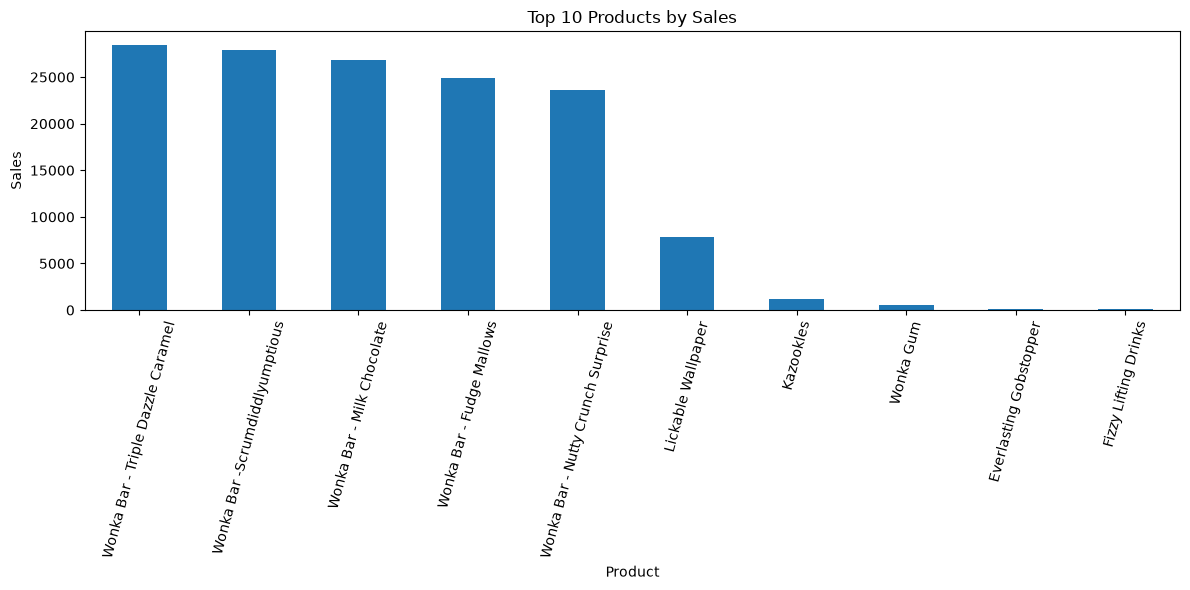

In [22]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
top_products.plot(kind="bar")
plt.title("Top 10 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

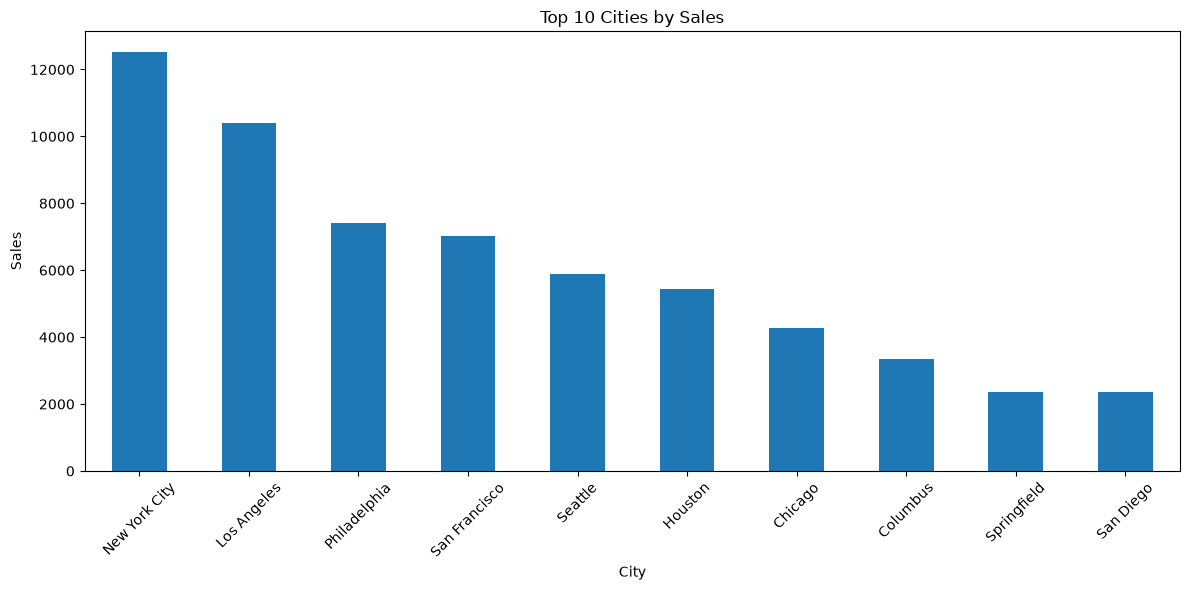

In [23]:
city_sales = (
    df.groupby("City")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
city_sales.plot(kind="bar")
plt.title("Top 10 Cities by Sales")
plt.xlabel("City")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

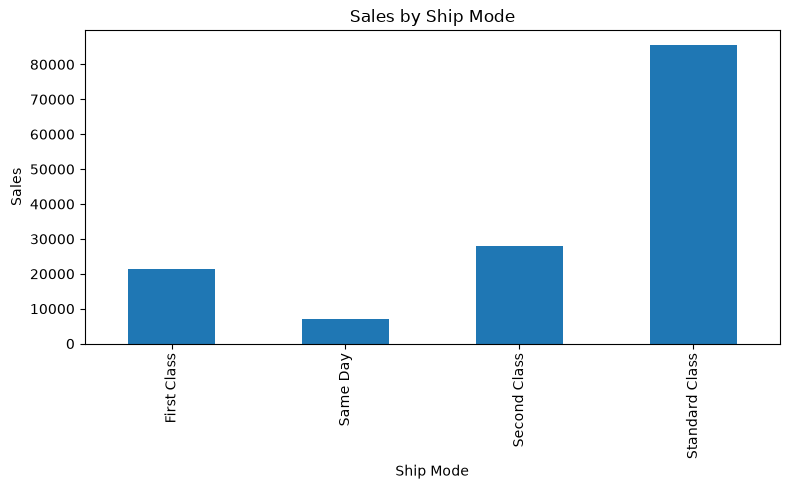

In [24]:
ship_mode_sales = df.groupby("Ship Mode")["Sales"].sum()

plt.figure(figsize=(8,5))
ship_mode_sales.plot(kind="bar")
plt.title("Sales by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

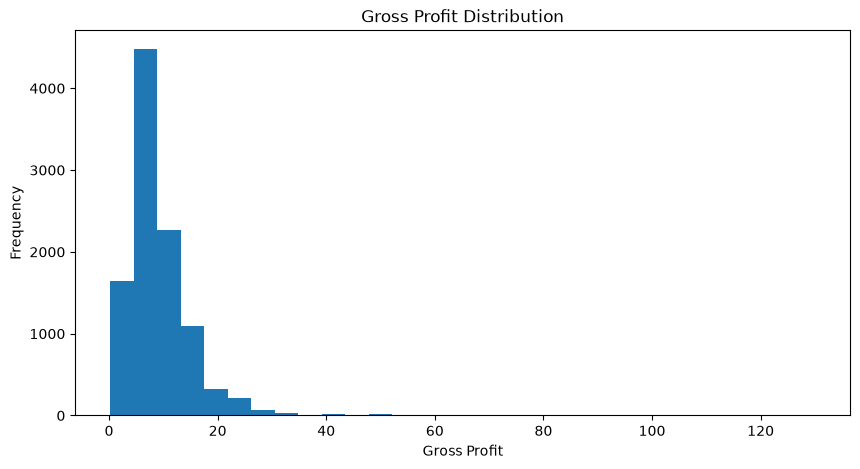

In [25]:
plt.figure(figsize=(10,5))
plt.hist(df["Gross Profit"], bins=30)
plt.title("Gross Profit Distribution")
plt.xlabel("Gross Profit")
plt.ylabel("Frequency")
plt.show()

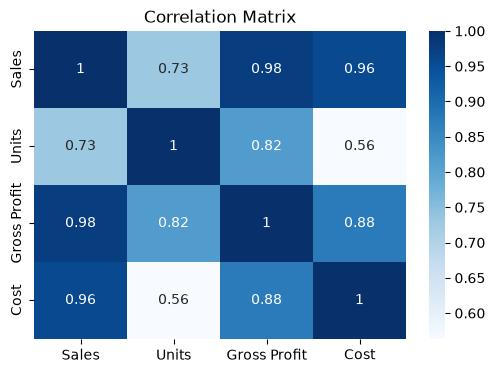

In [26]:
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(
    df[["Sales", "Units", "Gross Profit", "Cost"]].corr(),
    annot=True,
    cmap="Blues"
)
plt.title("Correlation Matrix")
plt.show()

In [ ]:
df = pd.read_csv("../data/Nassau Candy Distributor.csv")

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y"
)

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

In [29]:
df[["Order Date","Ship Date","Shipping Days"]].head()

,Order Date,Ship Date,Shipping Days
0,2024-01-03,2026-06-30,909
1,2024-01-04,2026-07-01,909
2,2024-01-04,2026-07-01,909
3,2024-01-04,2026-07-01,909
4,2024-01-05,2026-07-05,912


In [31]:
df = pd.read_csv("../data/Nassau Candy Distributor.csv")

df[["Order Date", "Ship Date"]].head(10)

,Order Date,Ship Date
0,03-01-2024,30-06-2026
1,04-01-2024,01-07-2026
2,04-01-2024,01-07-2026
3,04-01-2024,01-07-2026
4,05-01-2024,05-07-2026
5,06-01-2024,03-07-2026
6,06-01-2024,03-07-2026
7,06-01-2024,30-06-2026
8,06-01-2024,03-07-2026
9,06-01-2024,03-07-2026


In [32]:
df["Ship Date"].tail(10)

10184    25-06-2030
10185    25-06-2030
10186    26-06-2030
10187    28-06-2030
10188    26-06-2030
10189    26-06-2030
10190    26-06-2030
10191    26-06-2030
10192    26-06-2030
10193    26-06-2030
Name: Ship Date, dtype: str

In [33]:
print(df["Order Date"].min())
print(df["Order Date"].max())

print(df["Ship Date"].min())
print(df["Ship Date"].max())

01-01-2025
31-12-2025
01-01-2027
31-12-2029


In [34]:
# Reload from disk
df = pd.read_csv("../data/Nassau Candy Distributor.csv")

print(df.iloc[0])

Row ID                                       1
Order ID          US-2021-103800-CHO-MIL-31000
Order Date                          03-01-2024
Ship Date                           30-06-2026
Ship Mode                       Standard Class
Customer ID                             103800
Country/Region                   United States
City                                   Houston
State/Province                           Texas
Postal Code                              77095
Division                             Chocolate
Region                                Interior
Product ID                       CHO-MIL-31000
Product Name        Wonka Bar - Milk Chocolate
Sales                                      6.5
Units                                        2
Gross Profit                              4.22
Cost                                      2.28
Name: 0, dtype: object
